In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("/content/car data.csv")

# Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (301, 9)

Column names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

First five rows:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


Statistical Summary:


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


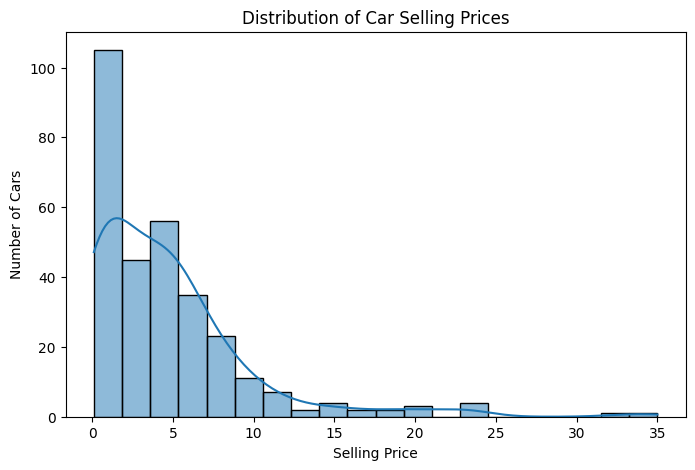

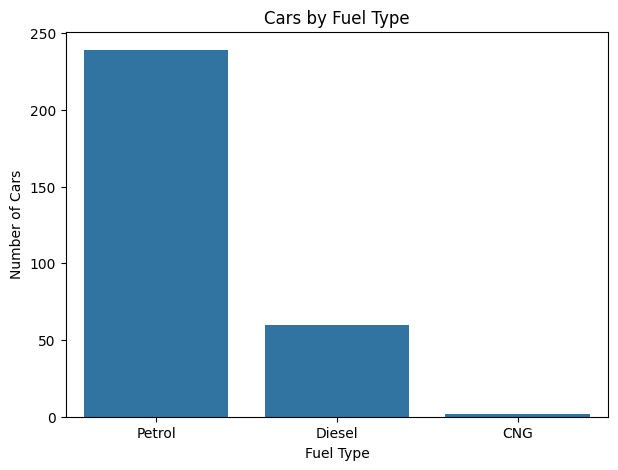

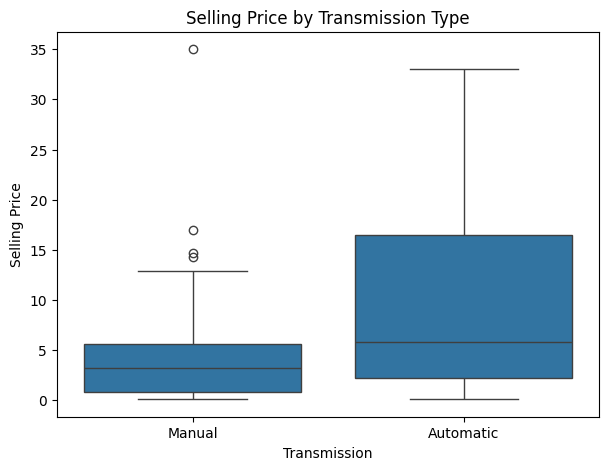

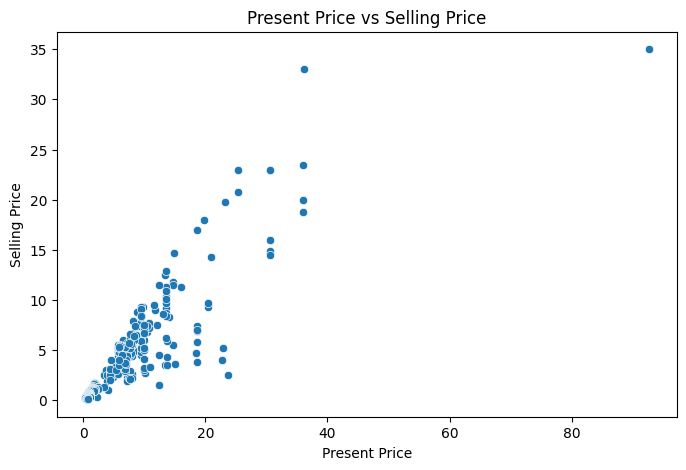

In [2]:

# Step 2: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

# Display basic statistical information
print("Statistical Summary:")
display(df.describe())

# 1. Distribution of selling prices
plt.figure(figsize=(8, 5))
sns.histplot(df["Selling_Price"], bins=20, kde=True)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()

# 2. Number of cars by fuel type
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Fuel_Type")
plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.show()

# 3. Selling price by transmission type
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Transmission", y="Selling_Price")
plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.show()

# 4. Relationship between present price and selling price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Present_Price", y="Selling_Price")
plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.show()


In [3]:

# Step 3: Prepare data for Machine Learning

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Input features (X) and target (y)
X = df.drop(columns=["Selling_Price", "Car_Name"])
y = df["Selling_Price"]

# Identify numerical and categorical columns
categorical_columns = ["Fuel_Type", "Selling_type", "Transmission"]
numerical_columns = ["Year", "Present_Price", "Driven_kms", "Owner"]

# Convert categorical values into numerical values
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_columns),
        ("numerical", "passthrough", numerical_columns)
    ]
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Features selected:", X.columns.tolist())
print("Data preparation completed successfully!")


Training records: 240
Testing records: 61
Features selected: ['Year', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']
Data preparation completed successfully!


In [4]:

# Step 4: Train the Machine Learning Model

# Create the complete machine-learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

# Predict car prices for the test data
y_pred = model.predict(X_test)

print("Model training completed successfully!")
print("Actual test records:", len(y_test))
print("Predictions generated:", len(y_pred))


Model training completed successfully!
Actual test records: 61
Predictions generated: 61


In [5]:

# Step 5: Evaluate Model Performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared Score (R²):", round(r2, 3))
print("R² Percentage:", round(r2 * 100, 2), "%")


MODEL PERFORMANCE
-------------------------
Mean Absolute Error (MAE): 0.61
Mean Squared Error (MSE): 0.87
Root Mean Squared Error (RMSE): 0.93
R-squared Score (R²): 0.962
R² Percentage: 96.23 %


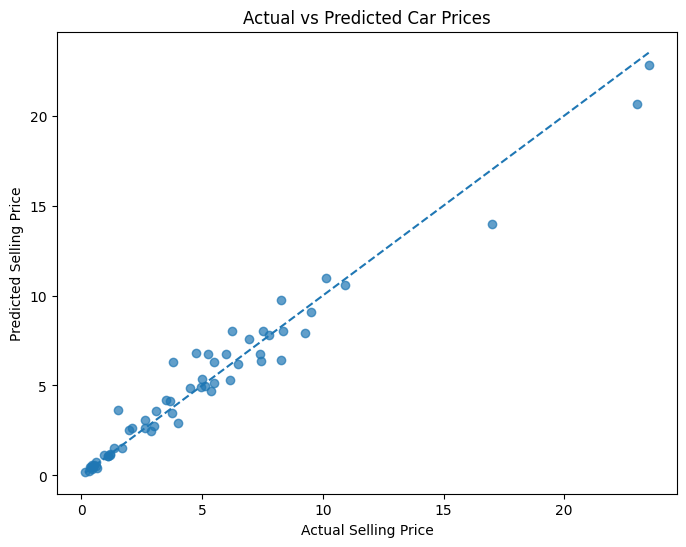

In [6]:

# Step 6: Actual vs Predicted Car Prices

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")
plt.show()


In [7]:

# Step 7: Compare Actual and Predicted Prices

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

results["Prediction Error"] = (
    results["Actual Price"] - results["Predicted Price"]
).round(2)

display(results.head(10).round(2))


,Actual Price,Predicted Price,Prediction Error
0,0.35,0.45,-0.10
1,10.11,11.00,-0.89
2,4.95,4.89,0.06
3,0.15,0.21,-0.06
4,6.95,7.56,-0.61
5,7.45,6.34,1.11
6,1.10,1.08,0.02
7,0.50,0.59,-0.09
8,0.45,0.47,-0.02
9,6.00,6.72,-0.72


In [8]:

# Step 8: Evaluate Model Performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("CAR PRICE PREDICTION - MODEL PERFORMANCE")
print("----------------------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared Score (R²):", round(r2, 3))
print("R-squared Percentage:", round(r2 * 100, 2), "%")


CAR PRICE PREDICTION - MODEL PERFORMANCE
----------------------------------------
Mean Absolute Error (MAE): 0.61
Mean Squared Error (MSE): 0.87
Root Mean Squared Error (RMSE): 0.93
R-squared Score (R²): 0.962
R-squared Percentage: 96.23 %


Feature Importance:


,Feature,Importance
8,numerical__Present_Price,0.883725
7,numerical__Year,0.055900
9,numerical__Driven_kms,0.036842
6,categorical__Transmission_Manual,0.006906
5,categorical__Transmission_Automatic,0.005974
1,categorical__Fuel_Type_Diesel,0.004315
2,categorical__Fuel_Type_Petrol,0.002129
4,categorical__Selling_type_Individual,0.002005
3,categorical__Selling_type_Dealer,0.001333
10,numerical__Owner,0.000859


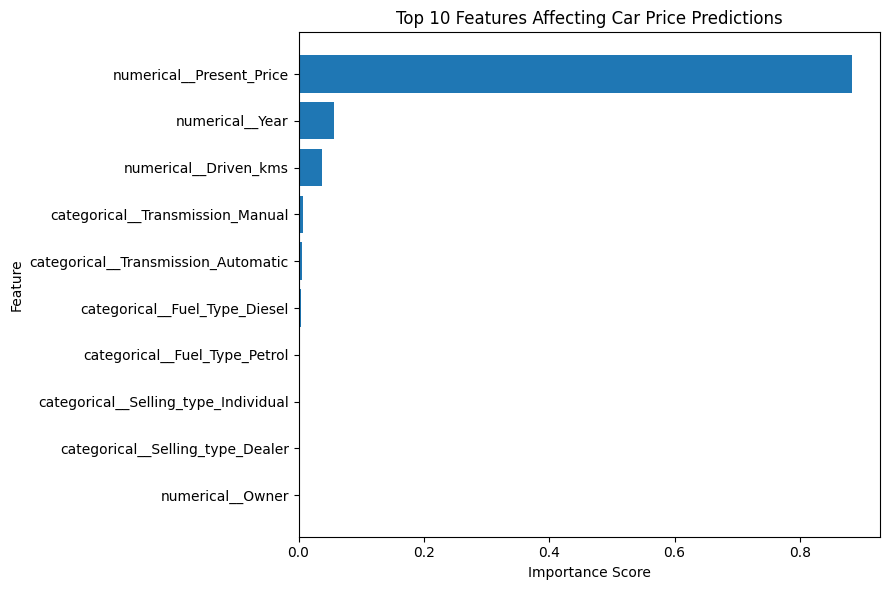

In [9]:

# Step 9: Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest model
rf_model = model.named_steps["regressor"]

# Get feature names after categorical encoding
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print("Feature Importance:")
display(importance_df)

# Plot the top 10 features
top_features = importance_df.head(10).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Features Affecting Car Price Predictions")
plt.tight_layout()
plt.show()
